# AP 155 Lab Exercise
---
## Exercise 8: Interpolation

_Instructions_:
- **Report figures:** Compare the original data with interpolated reconstructions. Include the synthetic sine example and the sampled real-world dataset, if available. For the real-world dataset, compare sampling levels of 50%, 30%, 10%, and 5%.
- **Report discussion:** Explain how the choice of interpolator and sampling level affects the reconstruction. Discuss limitations, including behavior outside the sampled domain.
- **Code:** Complete the code and ensure it is functional, readable, and efficient. Include concise Markdown documentation highlighting the critical steps.

### Student Information
- _Full Name (Last Name, First Name)_: Rivera, Kyle Florian
- _Student No._: 2024-16197
- _Section_: THU-TX-1

### Grading Information (c/o Lab Instructor)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figures | XX | 20 |
| Report discussion | XX | 20 |
| Code readability | XX | 20 |
| Code efficiency | XX | 20 |
| Code appropriateness | XX | 20 |
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_

---
## Section 1: Report

### Report figures

![Figure 1: Synthetic data interpolation](interpolations.png)

**Figure 1. Synthetic data interpolation.** 

![Figure 2: Errors from synthetic data interpolation](interpolation_error.png)

**Figure 2. Absolute errors from synthetic data interpolation.** 

![Figure 3: Real-world data reconstruction](dow_sample.png)

**Figure 3. Real-world data reconstruction.** 

### Report discussion

**Interpolator comparison:** Discuss how the interpolation methods differ and which reproduces the underlying function most accurately for the synthetic data.

The following interpolations are used, in order of computational cost:

- Nearest Interpolation - Sets the function value equal to the nearest value of a sample point. Function becomes steps.
- Linear Interpolation - Connects each pair of sample points with a straight line, resulting in a piecewise function defined over each interval between sample points.
- Quadratic Interpolation - Connects each sample points with parabolic curves.
- Cubic Interpolation - Approximates the data with cubic splines. 

In order to reproduce the underlying function accurately, one must use cubic interpolation as it describes the function with a 3rd degree polynomial, preventing kinks as it is continuous up to the 2nd derivative. However, the function is computationally more _expensive_ as it requires solving a tridiagonal matrix across the samples.

**Sampling-level comparison:** Discuss how reconstruction quality changes as the number of sampled data points decreases. Mention limitations and any visible artifacts.

As we decrease the sample points from $50\%$ to $5\%$, reconstruction quality reduces and the interpolated function doesn't fit the data as well. Moreover, lowering the sampled data points reduces the resolution, yielding poor accuracy (artifacts), especially when the function is not well-behaved, as seen in $5\%$, where instead of monotonically decreasing, the function varies wildly throughout Q1-Q3 of 2008.

### Other comments
- No comment

---
## Section 2: Code

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import interpolate

### Problem 1: Interpolation of synthetic data

Generate random samples from a known sine function, then compare several interpolation methods. The interpolators only reconstruct values within the sampled domain; they should not be treated as reliable extrapolators outside it.

In [2]:
x = np.linspace(-5, 5, 1000)
y = np.sin(x)
sample_size = 50

x_sample = np.random.choice(x, sample_size, replace = False)
y_sample = np.sin(x_sample)

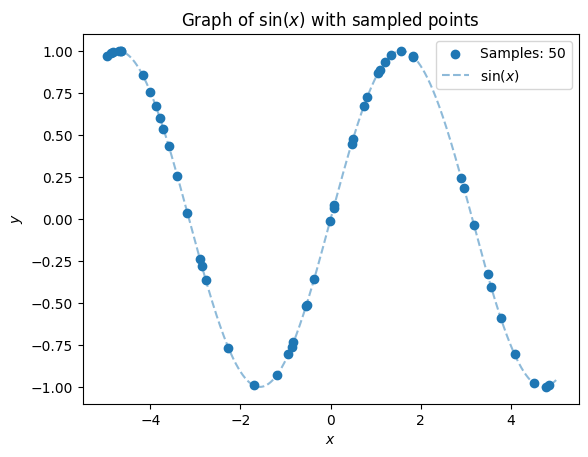

In [3]:
plt.scatter(x_sample, y_sample, label=f"Samples: {sample_size}")
plt.plot(x, y, ls="--", alpha=0.5, label=r"$\sin(x)$")
plt.title(r'Graph of $\sin(x)$ with sampled points')
plt.xlabel('$x$')
plt.ylabel('$y$')
plt.legend()
plt.show()

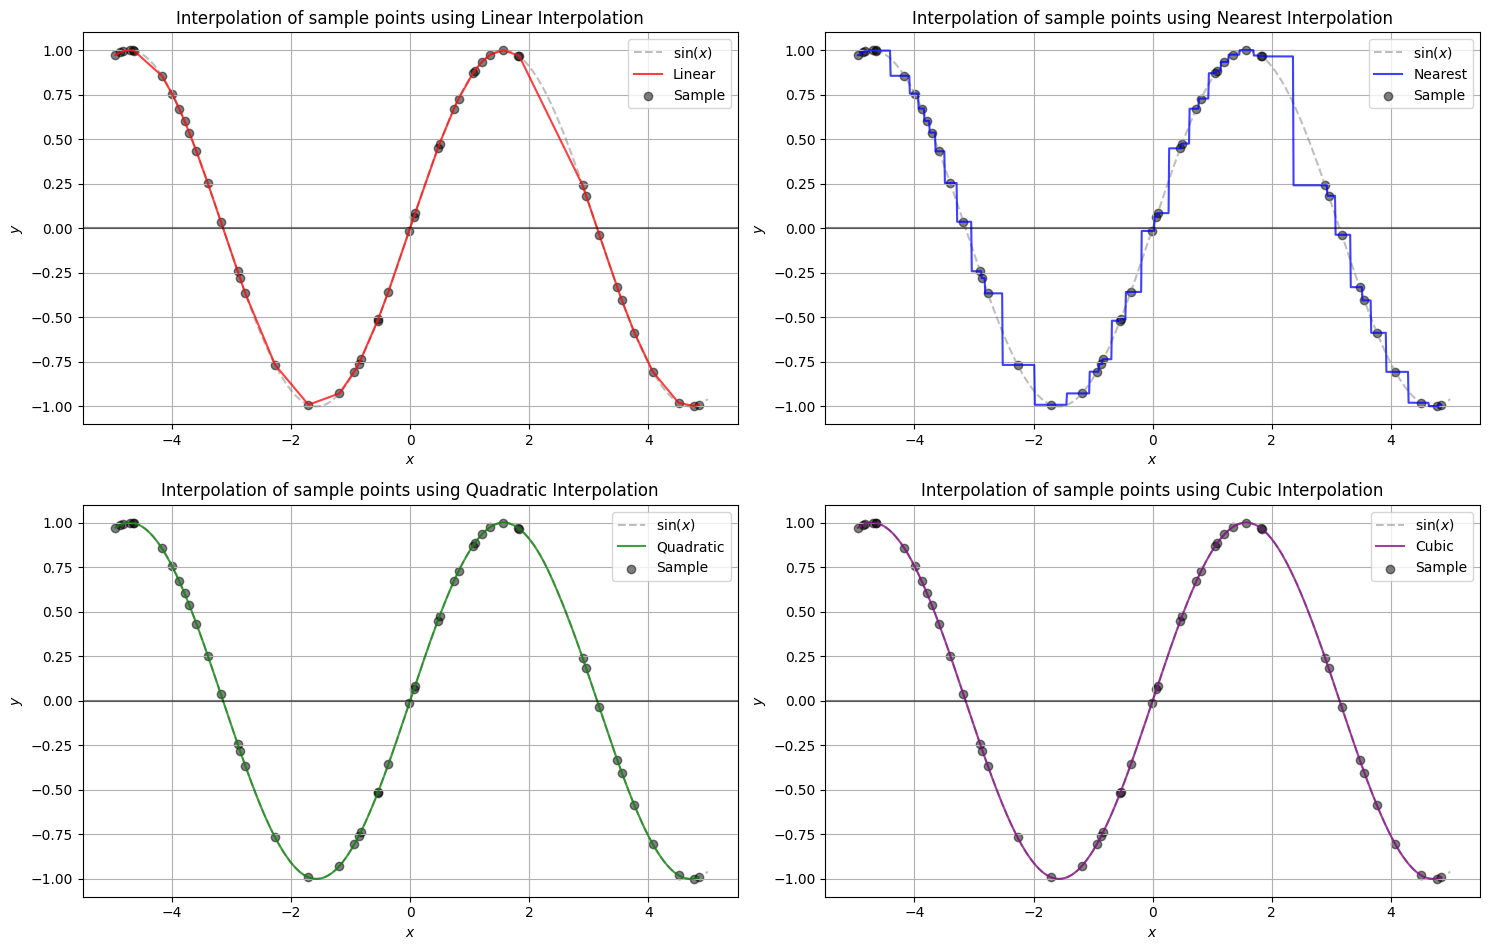

In [4]:
x_interp = np.linspace(np.min(x_sample), np.max(x_sample), 1000) # we make sure the plot for the interpolation does not exceed the sample points. we dont extrapolate

types = ['linear', 'nearest', 'quadratic', 'cubic']
methods = [interpolate.interp1d(x_sample, y_sample, kind=methods) for methods in types]

fig, axes = plt.subplots(2, 2, figsize = (15, 9.6))
axes = axes.flatten()

# self explanatory
colors = ['red', 'blue', 'green', 'purple']

# we plot the corresponding ordered pairs where the min/max occurs and see (visually) if it actually falls into where the derivative is zero.
for ax, color, interp, interp_name in zip(axes, colors, methods, types):
    # original sine function
    ax.plot(x, y, ls='--', label=r'$\sin(x)$', c='grey', alpha=0.5)

    title = interp_name.title()
    
    # sampled points and interpolated function
    ax.plot(x_interp, interp(x_interp), c=color, label=title, alpha=0.75)
    ax.scatter(x_sample, y_sample, c='black', label='Sample', alpha=0.5)
    
    ax.axhline(y=0, c='black', ls='-', alpha=0.5)
    ax.set_title(f"Interpolation of sample points using {title} Interpolation")
    ax.set_xlabel('$x$')
    ax.set_ylabel('$y$')
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.savefig("interpolations.png", dpi=600)
plt.show()

We can further visualize the error between the interpolated function and the original function. Notice that we use _absolute error_ and not relative error as to avoid the effects of catastrophic cancellation.

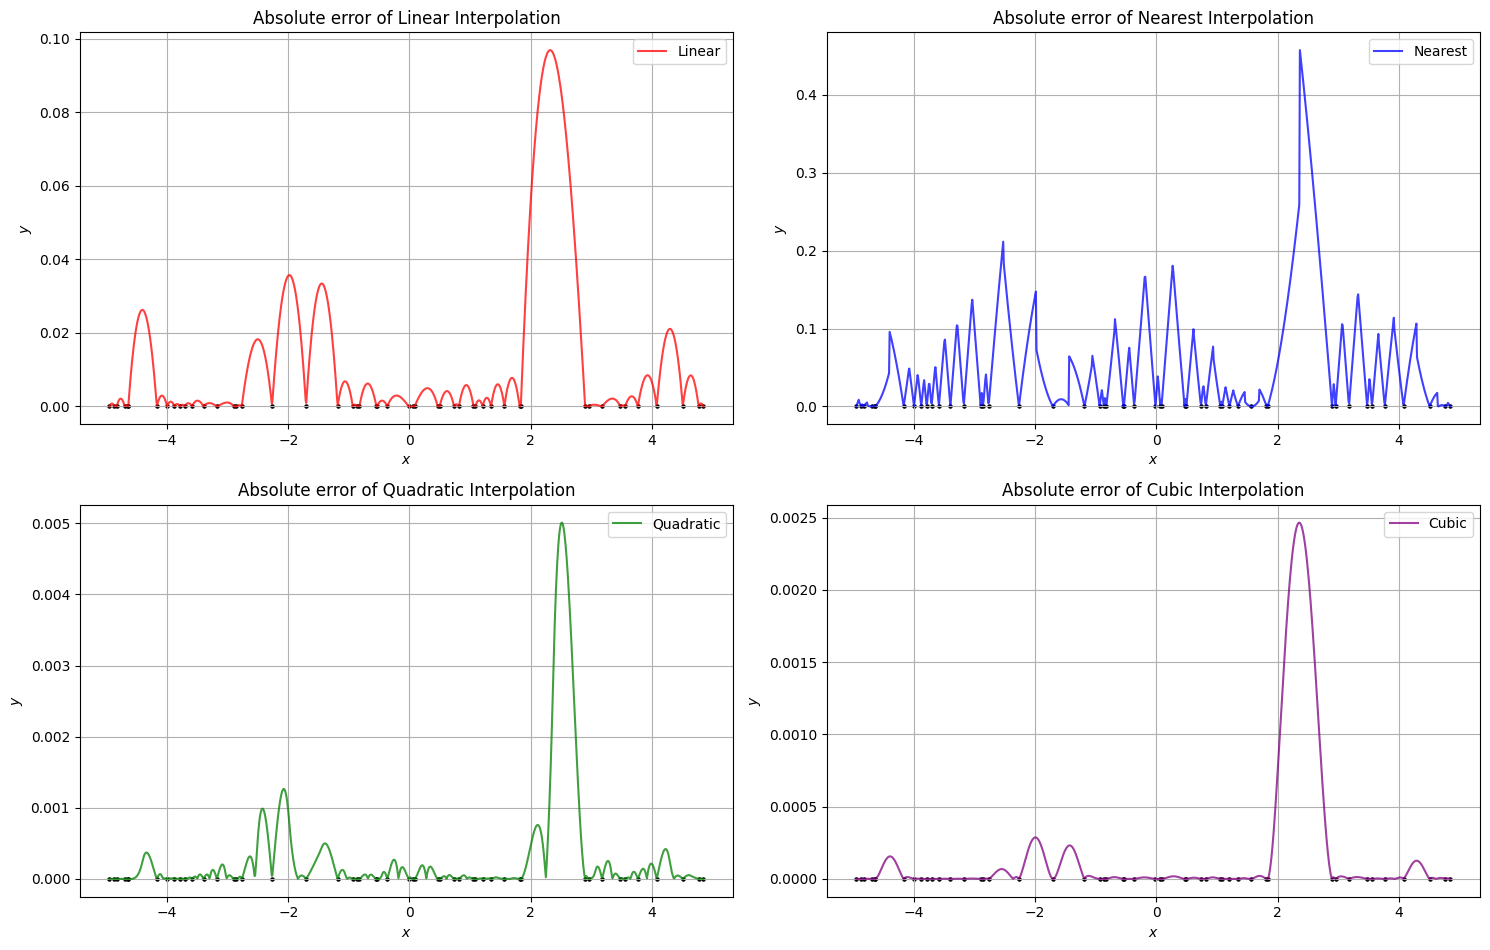

In [5]:
fig, axes = plt.subplots(2, 2, figsize = (15, 9.6))
axes = axes.flatten()

# we plot the corresponding ordered pairs where the min/max occurs and see (visually) if it actually falls into where the derivative is zero.
for ax, color, interp, interp_name in zip(axes, colors, methods, types):

    title = interp_name.title()

    # sampled points and interpolated function
    ax.plot(x_interp, abs(interp(x_interp) - np.sin(x_interp)) , c=color, label=title, alpha=0.75)
    ax.scatter(x_sample, np.zeros(len(x_sample)), c='black', s=5)

    ax.set_title(f"Absolute error of {title} Interpolation")
    ax.set_xlabel('$x$')
    ax.set_ylabel('$y$')
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.savefig("interpolation_error.png", dpi=600)
plt.show()

As seen in the graphs above, absolute error increases when the gap between the sampled points increases. Moreover, the error is, on average, at its peak at the midpoints of two sample points.

### Problem 2: Interpolation of real-world data

Load the Dow Jones time-series dataset, randomly retain a specified fraction of observations, and compare the reconstructed curve with the original series. The sampling fractions are 50%, 30%, 10%, and 5%. 

In [6]:
import datetime
import matplotlib.dates as mdates

In [7]:
with open("dow.txt", "r") as file:
    dow = np.array([float(line.strip()) for line in file])

date = list(range(len(dow)))
# setting up the coordinates of dow (date, price)
start_date = datetime.datetime(2006, 11, 27)  # Year, Month, Day
date_x = [start_date + datetime.timedelta(days=int(i)) for i in date] 

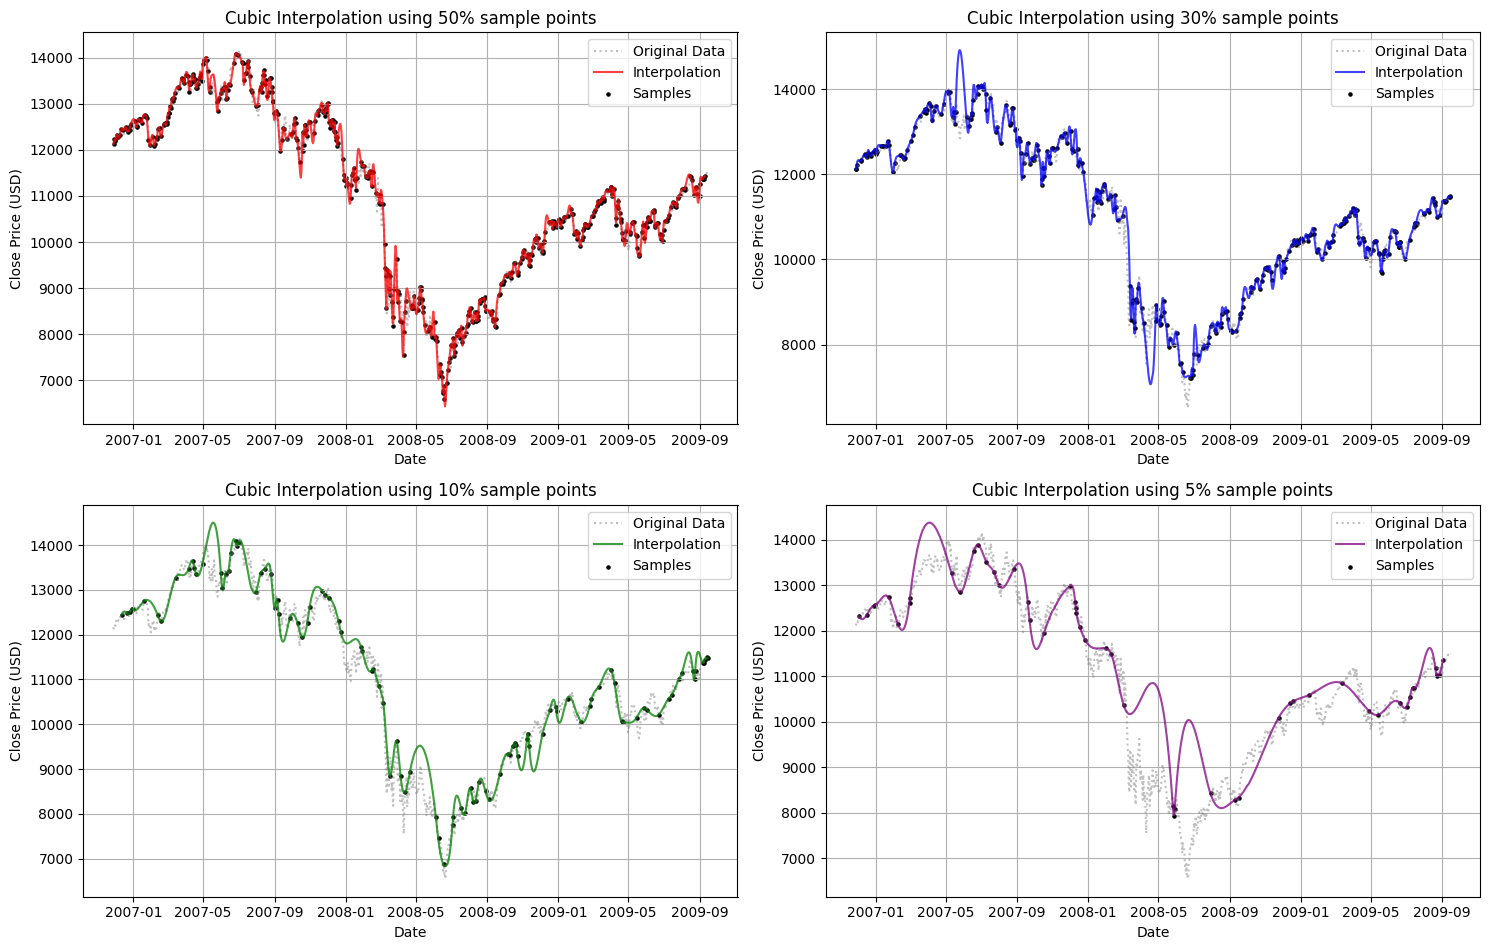

In [8]:
sample_percent = np.array([0.5, 0.3, 0.1, 0.05])
sample_size = [int(i*len(dow)) for i in sample_percent] # convert the sample percent into the fraction of the no. dates available

fig, axes = plt.subplots(2, 2, figsize = (15, 9.6))
axes = axes.flatten()
colors = ['red', 'blue', 'green', 'purple']

# we plot the corresponding ordered pairs where the min/max occurs and see (visually) if it actually falls into where the derivative is zero.
for ax, color, sample, percent in zip(axes, colors, sample_size, sample_percent):
    x_sample = np.random.choice(date, sample, replace = False)
    y_sample = [dow[i] for i in x_sample]

    interp = interpolate.interp1d(x_sample, y_sample, kind='cubic') # linear so it is easy to see what happens
    
    x = np.linspace(np.min(x_sample), np.max(x_sample), 1000)
    y = interp(x)

    # lets convert our x axis into a date format instead of counting days from zero
    date_x_interp = [start_date + datetime.timedelta(days=int(i)) for i in x]
    date_x_sample = [start_date + datetime.timedelta(days=int(i)) for i in x_sample]

    # original dow data 
    ax.plot(date_x, dow, ls=':', label=r'Original Data', c='grey', alpha=0.5)
    
    # sampled points and interpolated function
    ax.plot(date_x_interp, y, c=color, label='Interpolation', alpha=0.75)
    ax.scatter(date_x_sample, y_sample, c='black', label='Samples', s=5)
    
    ax.set_title(f"Cubic Interpolation using {percent:.0%} sample points")
    ax.set_xlabel('Date')
    ax.set_ylabel('Close Price (USD)')
    ax.legend()
    ax.grid(True, ls='-')

plt.tight_layout()
plt.savefig("dow_sample.png", dpi=1200)
plt.show()

In this problem, we varied the sample points and used cubic interpolation to further see how the amount of sample points affects the _quality_ of the interpolated function. We can see that the more sample points we can use in the interpolation, the more it looks like the original function, i.e., it looks more like how it actually appeared.

### Problem 3: Compare interpolation methods on the sampled real-world data

Use a single sampling fraction to compare linear, quadratic, and cubic interpolation. Higher-order interpolation can produce smoother curves, but it can also overshoot between sparse or rapidly changing observations.

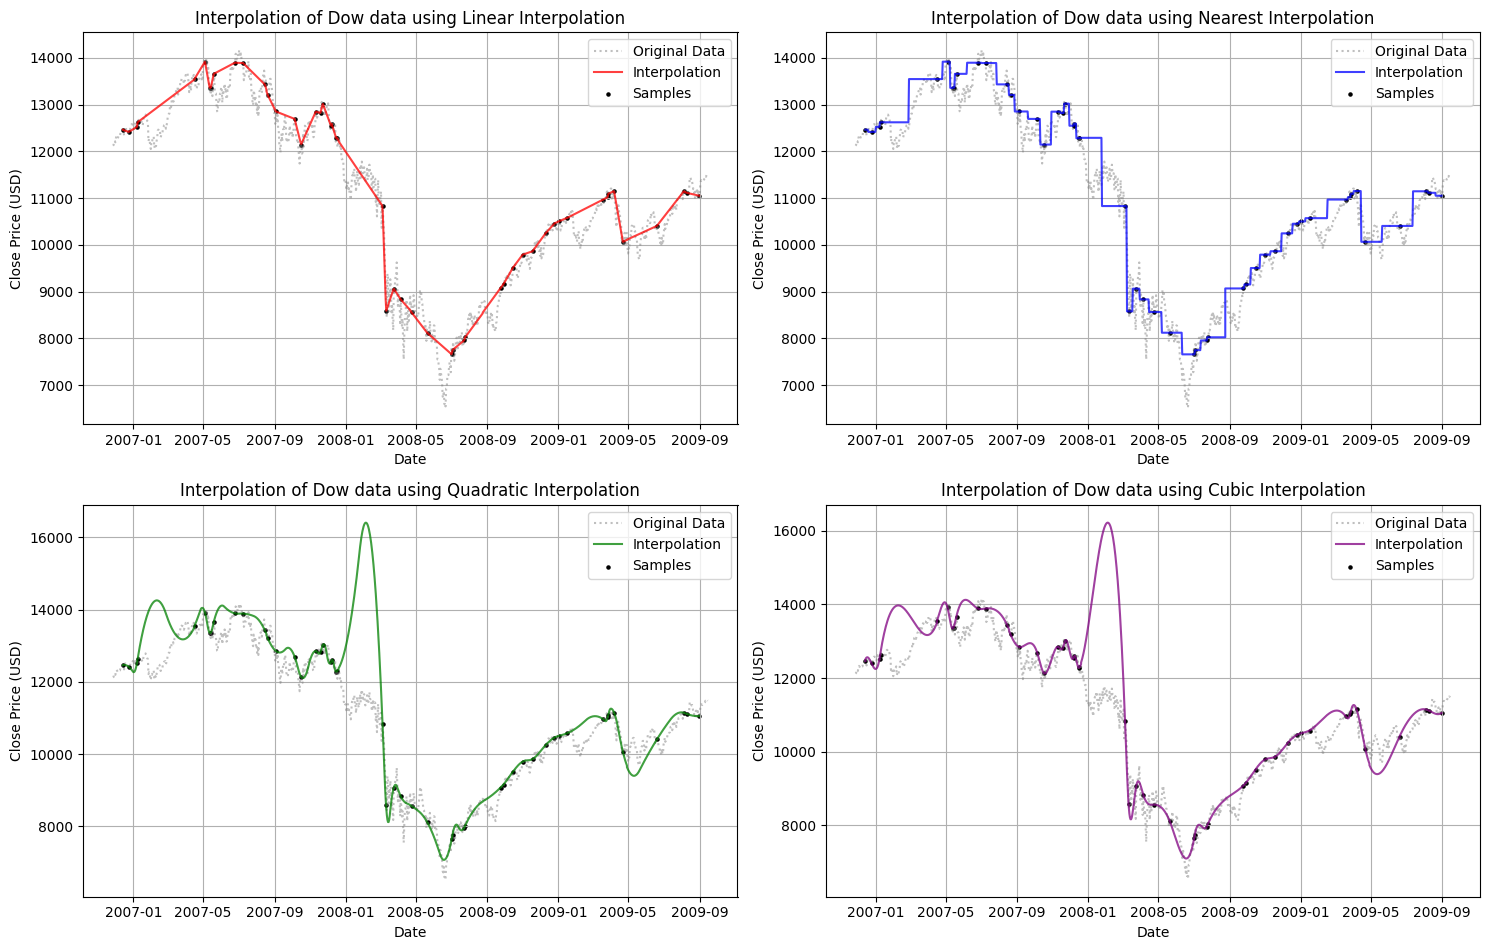

In [9]:
sample_size = int(0.05*len(dow)) # we use 10%

x_sample = np.random.choice(date, sample_size, replace = False)
y_sample = [dow[i] for i in x_sample]
x_interp = np.linspace(np.min(x_sample), np.max(x_sample), 1000) # we make sure the plot for the interpolation does not exceed the sample points.

types = ['linear', 'nearest', 'quadratic', 'cubic']
methods = [interpolate.interp1d(x_sample, y_sample, kind=methods) for methods in types]

fig, axes = plt.subplots(2, 2, figsize = (15, 9.6))
axes = axes.flatten()
colors = ['red', 'blue', 'green', 'purple']

# we plot the corresponding ordered pairs where the min/max occurs and see (visually) if it actually falls into where the derivative is zero.
for ax, color, interp, interp_name in zip(axes, colors, methods, types):
    # lets convert our x axis into a date format instead of counting days from zero
    date_x_interp = [start_date + datetime.timedelta(days=int(i)) for i in x_interp]
    date_x_sample = [start_date + datetime.timedelta(days=int(i)) for i in x_sample]

    # original dow values
    ax.plot(date_x, dow, ls=':', label=r'Original Data', c='grey', alpha=0.5)

    title = interp_name.title()

    # sampled points and interpolated function
    ax.plot(date_x_interp, interp(x_interp), c=color, label='Interpolation', alpha=0.75)
    ax.scatter(date_x_sample, y_sample, c='black', label='Samples', s=5)
    
    ax.set_title(f"Interpolation of Dow data using {title} Interpolation")
    ax.set_xlabel('Date')
    ax.set_ylabel('Close Price (USD)')
    ax.legend()
    ax.grid(True, ls='-')

plt.tight_layout()
plt.savefig("dow_interp.png", dpi=1200)
plt.show()

### Problem  code summary

In order to keep our code brief, we used for loops, iterating across the four methods for problem 1 and 3, while varying the sample sizes for problem 2.  Since we are tasked to interpolate the sampled points, we restrict the domain of the interpolated function to be $[x_0, x_n]$, where $x_0$ is the minimum x-value (first point) of the sampled points while $x_1$ is the maximum (last point).

---